# Athena synthetic pricing : a numerical example

In this notebook, we price a synthetic Athena autocall on the CAC 40 with a Heston model calibrated on the market, then we study its sensitivities and the features that can be added to the product.

**Base case**

| Term | Value |
|---|---|
| Underlying | CAC 40 index (price return, dividends not reinvested) |
| Pricing date | 12 February 2025 (market data of the calibration) |
| Maturity | 4 years |
| Observations | quarterly (16 dates), all callable |
| Autocall barrier | 100% of the initial level |
| Coupon | 6% p.a., snowball (paid at the call, $c \cdot t_k$) |
| Protection barrier | 60%, European (observed at maturity only) |
| Nominal | 100 |

**Payoff.** At each observation date $t_k$, if $S_{t_k} \geq 100\% \, S_{ref}$ the note is redeemed at $100 \, (1 + c \, t_k)$. If it is never called, it is redeemed at 100 when $S_T \geq 60\% \, S_{ref}$, and at $100 \, S_T / S_{ref}$ otherwise.

In [1]:
import os, sys
sys.path.append(os.path.abspath(os.path.join("..", "..")))                   # repo root: Equity_Models package
sys.path.append(os.path.abspath(os.path.join("..", "..", "Equity_Models")))  # flat imports inside Equity_Models
sys.path.append(os.path.abspath(".."))                                       # Products: market.py, notes_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston
from athena import Athena                                                    # Products/Athena/athena.py (self-contained)
from Equity_Models.monte_carlo import MonteCarloPricer
from Equity_Models.greeks import Greeks, plot_greeks_bars
from notes_analysis import plot_redemption_profiles, plot_call_probabilities, plot_scenarios

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Model

We use the Heston model calibrated on the CAC 40 implied volatility surface (`market.cac40_heston`). The paths are simulated on a weekly grid : the observation dates are quarterly and an American protection would use the Brownian bridge, so a daily grid is only needed for daily observations.

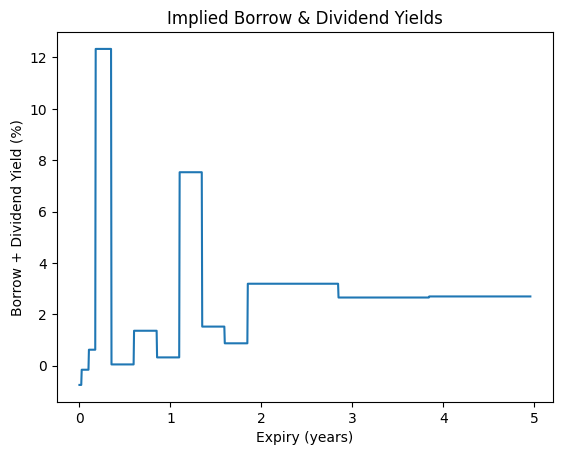

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [2]:
mkt = cac40_heston()
heston, S0 = mkt.heston, mkt.S0

pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42)
daily_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)

## 2. Pricing

`report` gathers the terms of the contract, the price (with its 95% Monte Carlo confidence interval), the fair coupon (the coupon that prices the note at par) and the scenario statistics.

In [3]:
base = Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6)
table, calls = base.report(pricer, heston, name="Base case", by_date=True)
table

Base case
Contract  maturity (years)                              4
          number of observations                       16
          observation frequency (years)              0.25
          coupon (% p.a.)                               6
          coupon type                            snowball
          first autocall barrier (%)                  100
          last autocall barrier (%)                   100
          step-down per observation (%)                 0
          first call date (years)                    0.25
          protection barrier (%)                       60
          protection type                        european
          redemption if knocked-in               standard
          capital guaranteed (%)                        0
          buffer (%)                                    0
          range accrual (%)                          none
          duo barrier (%)                            none
          duo coupon ratio                           none
          look back                                  none
          nominal                                     100
Pricing   price                                   97.7953
          95% confidence (+/-)                   0.109523
          price (% nominal)                       97.7953
          fair coupon (% p.a.)                    10.5382
Scenarios probability to reach maturity            0.1329
          probability of a capital loss           0.05218
          expected loss at maturity (% nominal)   3.05192
          expected life (years)                   1.03247
          expected number of coupons               0.8671
          expected coupon paid (% nominal)        3.00522

Probability of a call at each observation date, and cumulated :

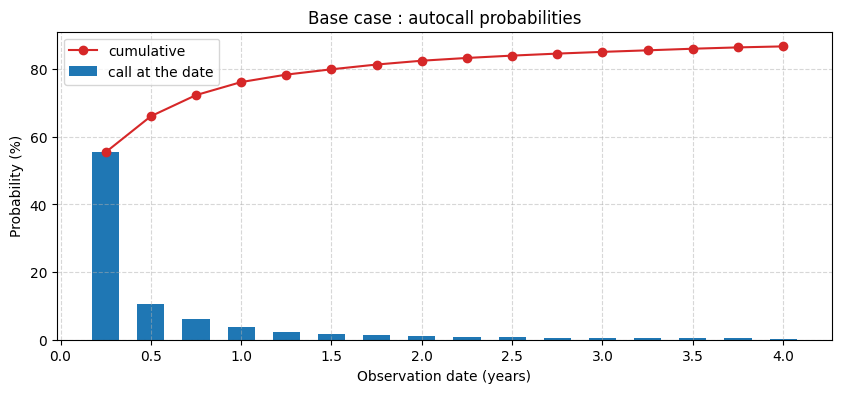

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(calls.index, 100 * calls["call probability"], width=0.15, label="call at the date")
ax.plot(calls.index, 100 * calls["cumulative"], "o-", color="tab:red", label="cumulative")
ax.set_xlabel("Observation date (years)")
ax.set_ylabel("Probability (%)")
ax.set_title("Base case : autocall probabilities")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()

Some simulated scenarios, grouped by outcome (called early, redeemed at par at maturity, capital loss) :

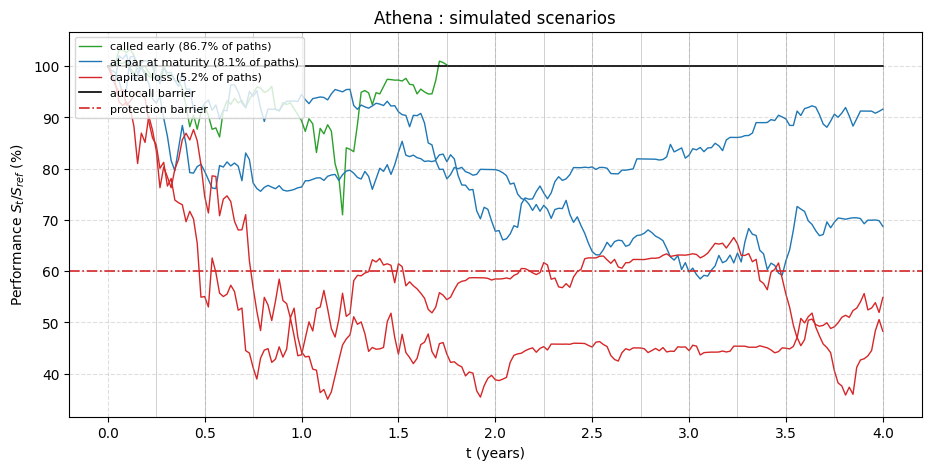

In [5]:
plot_scenarios(pricer, heston, base)

**Reading.** Most of the value comes from the first observation dates : the note is very likely to be called early, so its expected life is short and the coupon actually received is far below $4 \times 6\%$. The investor is short a down-and-in put : the capital loss is rare but large, since the redemption jumps from 100 to 60 at the protection barrier.

## 3. Sensitivities

To compare a variant with the base case, `compare` prices it, keeps its report in `reports` (used in the summary of section 4) and only displays the terms of the contract that differ from the base case.

In [6]:
reports = {"Base case": table}

def compare(name, note, note_pricer=pricer):
    """ Report of note next to the base case, with only the contract terms that differ. """
    reports[name] = note.report(note_pricer, heston, name=name)
    out = pd.concat([table, reports[name]], axis=1)
    contract = out.loc["Contract"].astype(str)
    changed = [("Contract", k) for k in contract.index[contract.nunique(axis=1) > 1]]
    return out.loc[changed + [i for i in out.index if i[0] != "Contract"]]


def sweep(parameter, values, **terms):
    """ Fair coupon and scenario statistics of the base case when one parameter moves. """
    rows = {}
    for x in values:
        note = Athena(4.0, S0, 0.06, **{**dict(frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6), **terms, parameter: x})
        stats = note.statistics(pricer, heston)
        rows[x] = {"fair coupon (% p.a.)": 100 * note.fair_coupon(pricer, heston),
                   "probability of a capital loss (%)": 100 * stats["probability of a capital loss"],
                   "expected loss (% nominal)": stats["expected loss at maturity (% nominal)"],
                   "expected life (years)": stats["expected life (years)"]}
    return pd.DataFrame(rows).T.rename_axis(parameter)


def plot_sweep(df, title):
    fig, axes = plt.subplots(1, len(df.columns), figsize=(4.2 * len(df.columns), 3.4))
    for ax, column in zip(axes, df.columns):
        ax.plot(100 * df.index, df[column], "o-")
        ax.set_title(column, fontsize=10)
        ax.set_xlabel(f"{df.index.name} (%)")
        ax.grid(True, linestyle="--", alpha=0.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 3.1 Protection barrier

In [7]:
compare("Protection 80%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.8))

Base case Protection 80%
Contract  protection barrier (%)                       60             80
Pricing   price                                   97.7953        96.5991
          95% confidence (+/-)                   0.109523       0.120649
          price (% nominal)                       97.7953        96.5991
          fair coupon (% p.a.)                    10.5382         13.003
Scenarios probability to reach maturity            0.1329         0.1329
          probability of a capital loss           0.05218        0.09568
          expected loss at maturity (% nominal)   3.05192        4.34222
          expected life (years)                   1.03247        1.03247
          expected number of coupons               0.8671         0.8671
          expected coupon paid (% nominal)        3.00522        3.00522

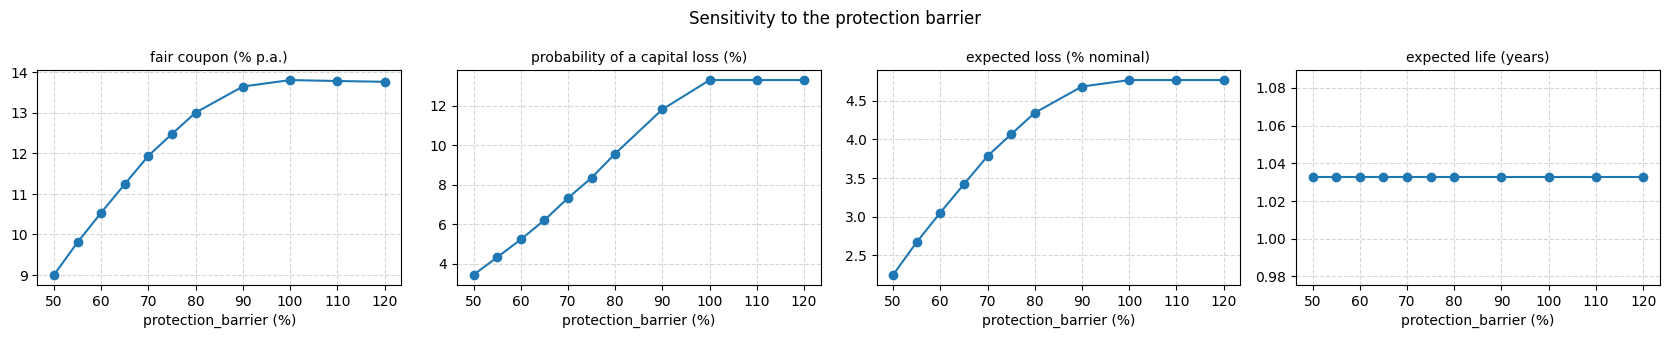

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years)
protection_barrier,,,,
0.5,9.00468,3.428,2.24682,1.03247
0.55,9.80869,4.316,2.66903,1.03247
0.6,10.5382,5.218,3.05192,1.03247
0.65,11.2411,6.194,3.4177,1.03247
0.7,11.9396,7.318,3.78266,1.03247
0.75,12.4773,8.342,4.06529,1.03247
0.8,13.003,9.568,4.34222,1.03247
0.9,13.6443,11.808,4.68229,1.03247
1,13.8031,13.29,4.76606,1.03247


In [27]:
protection_sweep = sweep("protection_barrier", [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0, 1.1, 1.2])
plot_sweep(protection_sweep, "Sensitivity to the protection barrier")
protection_sweep

A higher protection barrier means that the investor sells a more valuable down-and-in put : the capital is lost more often, and the fair coupon increases to pay for it. The call probabilities and the expected life do not move, since the protection only matters at maturity.

### 3.2 Autocall barrier

In [9]:
compare("Autocall 110%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.1, protection_barrier=0.6))

Base case Autocall 110%
Contract  first autocall barrier (%)                  100           110
          last autocall barrier (%)                   100           110
Pricing   price                                   97.7953        94.333
          95% confidence (+/-)                   0.109523      0.116345
          price (% nominal)                       97.7953        94.333
          fair coupon (% p.a.)                    10.5382       12.6875
Scenarios probability to reach maturity            0.1329       0.37564
          probability of a capital loss           0.05218        0.1048
          expected loss at maturity (% nominal)   3.05192       6.03887
          expected life (years)                   1.03247       2.39018
          expected number of coupons               0.8671       0.62436
          expected coupon paid (% nominal)        3.00522       5.32575

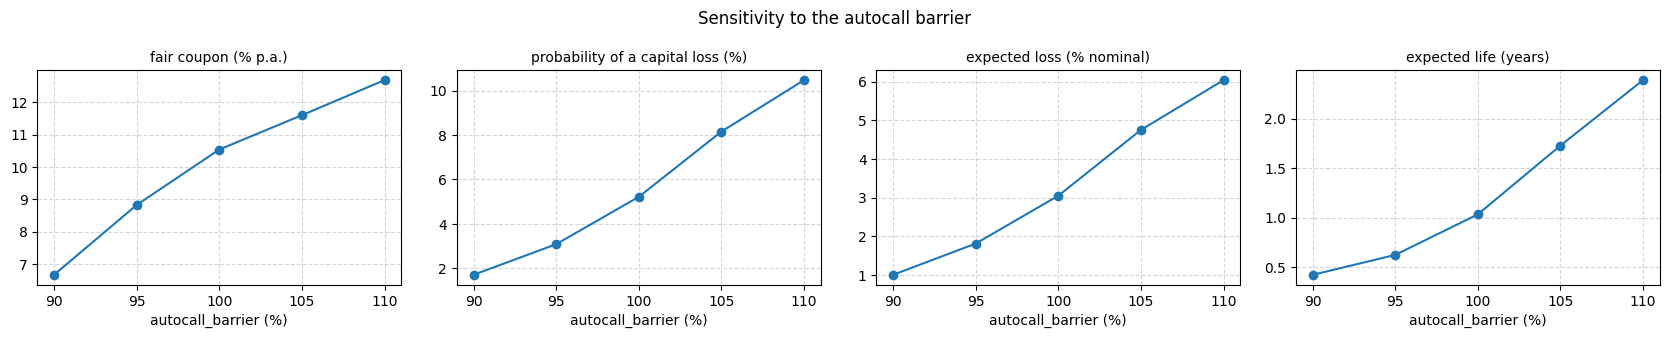

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years)
autocall_barrier,,,,
0.9,6.65907,1.704,1.00956,0.42151
0.95,8.8214,3.084,1.81631,0.62259
1,10.5382,5.218,3.05192,1.03247
1.05,11.6004,8.16,4.75168,1.72821
1.1,12.6875,10.48,6.03887,2.39018


In [10]:
autocall_sweep = sweep("autocall_barrier", [0.9, 0.95, 1.0, 1.05, 1.1])
plot_sweep(autocall_sweep, "Sensitivity to the autocall barrier")
autocall_sweep

A higher autocall barrier makes the call less likely : the note lives longer, more paths reach maturity and are exposed to the put, so the fair coupon increases.

## 4. Features of Athena products

We now look at the features that can be added to the Athena product and at their impact on the price. Every variant is compared with the base case, all the other terms being equal.

### 4.1 Observation frequency

The autocall barrier is now observed every day (1008 observation dates) instead of every quarter. The daily grid is needed, since the weekly one is too coarse for these dates.

In [11]:
compare("Daily observation", Athena(4.0, S0, 0.06, frequency=1/252, autocall_barrier=1.0, protection_barrier=0.6), daily_pricer)

Base case Daily observation
Contract  number of observations                       16              1008
          observation frequency (years)              0.25        0.00396825
          first call date (years)                    0.25        0.00396825
Pricing   price                                   97.7953            99.651
          95% confidence (+/-)                   0.109523          0.049185
          price (% nominal)                       97.7953            99.651
          fair coupon (% p.a.)                    10.5382           11.7368
Scenarios probability to reach maturity            0.1329           0.01796
          probability of a capital loss           0.05218           0.00778
          expected loss at maturity (% nominal)   3.05192          0.455526
          expected life (years)                   1.03247          0.134455
          expected number of coupons               0.8671           0.98204
          expected coupon paid (% nominal)        3.00522          0.375689

### 4.2 Step-down barrier

The autocall barrier decreases by 1% at each observation, from 100% to 85% at maturity. The call becomes easier over time.

In [12]:
compare("Step-down 1%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, step_down=0.01))

Base case Step-down 1%
Contract  last autocall barrier (%)                   100           85
          step-down per observation (%)                 0            1
Pricing   price                                   97.7953      98.8083
          95% confidence (+/-)                   0.109523      0.10446
          price (% nominal)                       97.7953      98.8083
          fair coupon (% p.a.)                    10.5382      8.23821
Scenarios probability to reach maturity            0.1329      0.08118
          probability of a capital loss           0.05218       0.0444
          expected loss at maturity (% nominal)   3.05192      2.61864
          expected life (years)                   1.03247       0.8738
          expected number of coupons               0.8671      0.91882
          expected coupon paid (% nominal)        3.00522      3.29448

### 4.3 Airbag

The put is struck at the protection barrier : below 60%, the redemption is $100 \, S_T / (0.6 \, S_{ref})$. There is no more loss jump at the barrier.

In [13]:
compare("Airbag", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, put_strike=0.6))

Base case    Airbag
Contract  redemption if knocked-in               standard    airbag
Pricing   price                                   97.7953   99.1098
          95% confidence (+/-)                   0.109523 0.0746021
          price (% nominal)                       97.7953   99.1098
          fair coupon (% p.a.)                    10.5382   7.83238
Scenarios probability to reach maturity            0.1329    0.1329
          probability of a capital loss           0.05218   0.05218
          expected loss at maturity (% nominal)   3.05192   1.60787
          expected life (years)                   1.03247   1.03247
          expected number of coupons               0.8671    0.8671
          expected coupon paid (% nominal)        3.00522   3.00522

### 4.4 Buffer

The first 10% of decline is absorbed by the issuer : below 90%, the investor loses one for one, $100 \, (S_T / S_{ref} + 10\%)$, without loss jump.

In [14]:
compare("Buffer 10%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.9, buffer=0.1))

Base case  Buffer 10%
Contract  protection barrier (%)                       60          90
          redemption if knocked-in               standard  buffer 10%
          buffer (%)                                    0          10
Pricing   price                                   97.7953     97.3663
          95% confidence (+/-)                   0.109523     0.10254
          price (% nominal)                       97.7953     97.3663
          fair coupon (% p.a.)                    10.5382     11.4234
Scenarios probability to reach maturity            0.1329      0.1329
          probability of a capital loss           0.05218     0.11808
          expected loss at maturity (% nominal)   3.05192     3.50149
          expected life (years)                   1.03247     1.03247
          expected number of coupons               0.8671      0.8671
          expected coupon paid (% nominal)        3.00522     3.00522

### 4.5 Guaranteed capital

The redemption at maturity is floored : `floor=1.0` guarantees 100% of the capital, `floor=0.9` guarantees 90%.

In [15]:
compare("Guaranteed 100%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, floor=1.0))

Base case Guaranteed 100%
Contract  capital guaranteed (%)                        0             100
Pricing   price                                   97.7953         100.568
          95% confidence (+/-)                   0.109523       0.0362875
          price (% nominal)                       97.7953         100.568
          fair coupon (% p.a.)                    10.5382         4.82995
Scenarios probability to reach maturity            0.1329          0.1329
          probability of a capital loss           0.05218               0
          expected loss at maturity (% nominal)   3.05192               0
          expected life (years)                   1.03247         1.03247
          expected number of coupons               0.8671          0.8671
          expected coupon paid (% nominal)        3.00522         3.00522

In [16]:
compare("Guaranteed 90%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, floor=0.9))

Base case Guaranteed 90%
Contract  capital guaranteed (%)                        0             90
Pricing   price                                   97.7953        100.094
          95% confidence (+/-)                   0.109523      0.0458459
          price (% nominal)                       97.7953        100.094
          fair coupon (% p.a.)                    10.5382        5.80665
Scenarios probability to reach maturity            0.1329         0.1329
          probability of a capital loss           0.05218        0.05218
          expected loss at maturity (% nominal)   3.05192         0.5218
          expected life (years)                   1.03247        1.03247
          expected number of coupons               0.8671         0.8671
          expected coupon paid (% nominal)        3.00522        3.00522

### 4.6 Coupon range accrual

The coupon only accrues on the (weekly) simulation dates where $80\% \leq S_t / S_{ref} \leq 120\%$.

In [17]:
compare("Range accrual 80-120%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, accrual_range=(0.8, 1.2)))

Base case  \
Contract  range accrual (%)                          none   
Pricing   price                                   97.7953   
          95% confidence (+/-)                   0.109523   
          price (% nominal)                       97.7953   
          fair coupon (% p.a.)                    10.5382   
Scenarios probability to reach maturity            0.1329   
          probability of a capital loss           0.05218   
          expected loss at maturity (% nominal)   3.05192   
          expected life (years)                   1.03247   
          expected number of coupons               0.8671   
          expected coupon paid (% nominal)        3.00522   

                                                Range accrual 80-120%  
Contract  range accrual (%)                                 [80, 120]  
Pricing   price                                               97.6764  
          95% confidence (+/-)                               0.108702  
          price (% nominal)                                   97.6764  
          fair coupon (% p.a.)                                10.9862  
Scenarios probability to reach maturity                        0.1329  
          probability of a capital loss                       0.05218  
          expected loss at maturity (% nominal)               3.05192  
          expected life (years)                               1.03247  
          expected number of coupons                           0.8671  
          expected coupon paid (% nominal)                     2.8789

### 4.7 Duo mechanism

Two call levels : the note is called with the full coupon above 100%, and with half of the coupon between 90% and 100%.

In [18]:
compare("Duo 90% / 50%", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, duo_barrier=0.9, duo_coupon_ratio=0.5))

Base case Duo 90% / 50%
Contract  duo barrier (%)                            none            90
          duo coupon ratio                           none           0.5
Pricing   price                                   97.7953       99.3724
          95% confidence (+/-)                   0.109523     0.0693994
          price (% nominal)                       97.7953       99.3724
          fair coupon (% p.a.)                    10.5382       8.85779
Scenarios probability to reach maturity            0.1329       0.03132
          probability of a capital loss           0.05218       0.01704
          expected loss at maturity (% nominal)   3.05192       1.00956
          expected life (years)                   1.03247       0.42151
          expected number of coupons               0.8671       0.96868
          expected coupon paid (% nominal)        3.00522        1.3335

### 4.8 Look back

The reference level $S_{ref}$ is the minimum of the index over the first month instead of the initial fixing (`lookback_type='average'` gives an Asian fixing).

In [19]:
compare("Look back min 1m", Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6, lookback=1/12, lookback_type='min'))

Base case     Look back min 1m
Contract  look back                                  none  min over 0.0833333y
Pricing   price                                   97.7953              98.7453
          95% confidence (+/-)                   0.109523            0.0953223
          price (% nominal)                       97.7953              98.7453
          fair coupon (% p.a.)                    10.5382              9.07992
Scenarios probability to reach maturity            0.1329               0.0903
          probability of a capital loss           0.05218              0.03572
          expected loss at maturity (% nominal)   3.05192              2.08984
          expected life (years)                   1.03247             0.778975
          expected number of coupons               0.8671               0.9097
          expected coupon paid (% nominal)        3.00522              2.50665

### 4.9 Summary

All the variants priced above, with a coupon of 6% p.a. :

In [20]:
summary = pd.concat(reports.values(), axis=1).drop(index="Contract", level=0).droplevel(0).T.astype(float)
summary = summary.drop(columns=["price (% nominal)"])
summary.sort_values("fair coupon (% p.a.)")

,price,95% confidence (+/-),fair coupon (% p.a.),probability to reach maturity,probability of a capital loss,expected loss at maturity (% nominal),expected life (years),expected number of coupons,expected coupon paid (% nominal)
Guaranteed 100%,100.568,0.0362875,4.82995,0.1329,0,0,1.03247,0.8671,3.00522
Guaranteed 90%,100.094,0.0458459,5.80665,0.1329,0.05218,0.5218,1.03247,0.8671,3.00522
Airbag,99.1098,0.0746021,7.83238,0.1329,0.05218,1.60787,1.03247,0.8671,3.00522
Step-down 1%,98.8083,0.10446,8.23821,0.08118,0.0444,2.61864,0.8738,0.91882,3.29448
Duo 90% / 50%,99.3724,0.0693994,8.85779,0.03132,0.01704,1.00956,0.42151,0.96868,1.3335
Look back min 1m,98.7453,0.0953223,9.07992,0.0903,0.03572,2.08984,0.778975,0.9097,2.50665
Base case,97.7953,0.109523,10.5382,0.1329,0.05218,3.05192,1.03247,0.8671,3.00522
Range accrual 80-120%,97.6764,0.108702,10.9862,0.1329,0.05218,3.05192,1.03247,0.8671,2.8789
Buffer 10%,97.3663,0.10254,11.4234,0.1329,0.11808,3.50149,1.03247,0.8671,3.00522
Daily observation,99.651,0.049185,11.7368,0.01796,0.00778,0.455526,0.134455,0.98204,0.375689


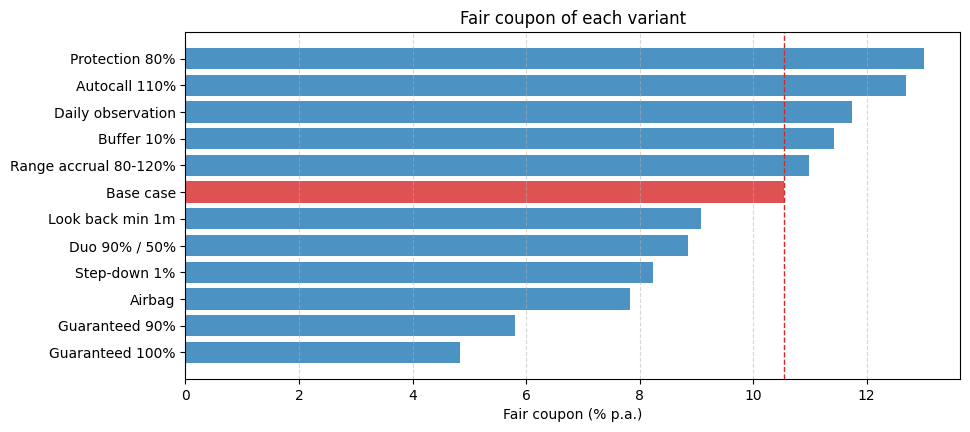

In [21]:
fair = summary["fair coupon (% p.a.)"].sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["tab:red" if name == "Base case" else "tab:blue" for name in fair.index]
ax.barh(fair.index, fair.values, color=colors, alpha=0.8)
ax.axvline(fair["Base case"], color="tab:red", linestyle="--", linewidth=1)
ax.set_xlabel("Fair coupon (% p.a.)")
ax.set_title("Fair coupon of each variant")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.show()

Redemption at maturity of the variants that change the capital protection, if the note was never called :

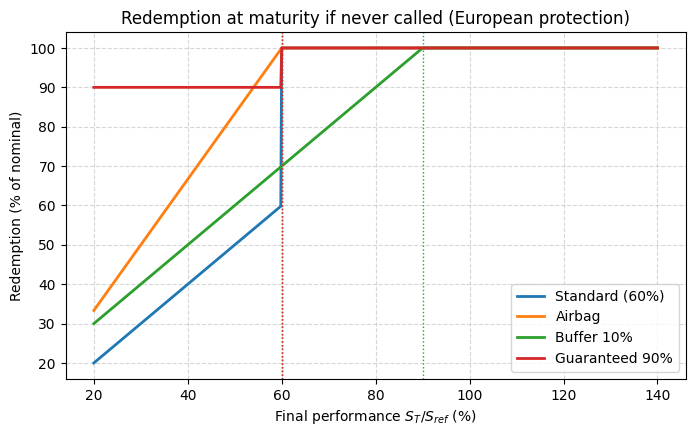

<Axes: title={'center': 'Redemption at maturity if never called (European protection)'}, xlabel='Final performance $S_T / S_{ref}$ (%)', ylabel='Redemption (% of nominal)'>

In [22]:
plot_redemption_profiles({
    "Standard (60%)": base,
    "Airbag": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, put_strike=0.6),
    "Buffer 10%": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.9, buffer=0.1),
    "Guaranteed 90%": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, floor=0.9),
})

Call probabilities of the variants that change the autocall mechanism :

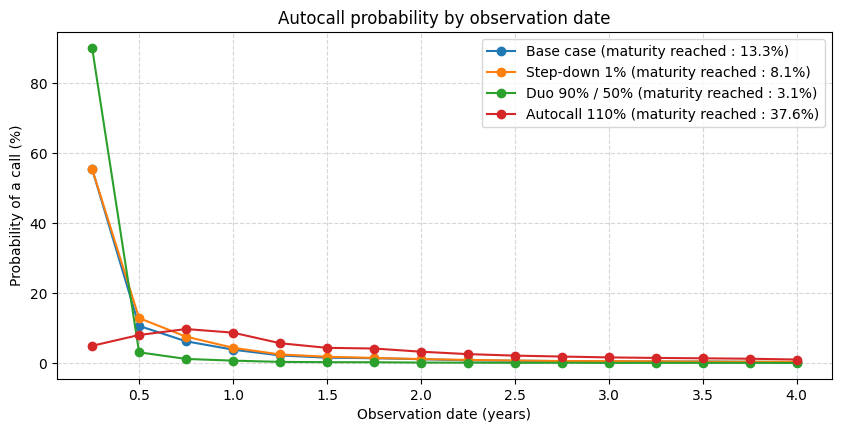

In [23]:
plot_call_probabilities(pricer, heston, {
    "Base case": base,
    "Step-down 1%": Athena(4.0, S0, 0.06, frequency=0.25, step_down=0.01),
    "Duo 90% / 50%": Athena(4.0, S0, 0.06, frequency=0.25, duo_barrier=0.9, duo_coupon_ratio=0.5),
    "Autocall 110%": Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.1),
})

**Reading.** The features that make the call easier (step-down, duo, look back) or that reduce the loss at maturity (airbag, guaranteed capital) are more valuable for the investor, so their fair coupon is lower than in the base case. The features that make the loss more likely (higher protection barrier or autocall barrier, buffer, which starts losing below 90%) or the coupon smaller (range accrual) are paid by a higher fair coupon.

The daily observation is the exception : the call is almost certain within a few weeks, so the loss nearly disappears, but the snowball coupon $c \, t_k$ is then paid on a very short life. A much higher coupon rate is needed to price the note at par.

## 5. Greeks

Greeks of the base case and of the variants that change the capital protection, by finite differences on the same paths (delta per unit of spot, vega per vol point, rho per +1% of rates, theta per day).

In [24]:
greek_notes = {
    "Base case": base,
    "Airbag": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, put_strike=0.6),
    "Guaranteed 90%": Athena(4.0, S0, 0.06, frequency=0.25, protection_barrier=0.6, floor=0.9),
    "Step-down 1%": Athena(4.0, S0, 0.06, frequency=0.25, step_down=0.01),
}
greeks = Greeks(pricer).table(heston, list(greek_notes.values()), labels=list(greek_notes), with_stderr=True)
greeks[[c for c in greeks.columns if not c.endswith("stderr")]]

,price,delta,gamma,vega,vanna,volga,rho,theta
Base case,97.7953,0.00469712,-8.58043e-06,-0.315332,0.000244823,-0.0220015,-0.209613,0.00476735
Airbag,99.1098,0.00260267,-6.21034e-06,-0.205024,0.000169848,-0.0228362,-0.485512,0.00244142
Guaranteed 90%,100.094,0.00113651,-3.73467e-06,-0.0663329,6.90938e-05,-0.0111808,-0.683101,0.00190582
Step-down 1%,98.8083,0.00224738,-7.30446e-06,-0.298906,0.000285702,-0.0111481,-0.421188,0.00396802


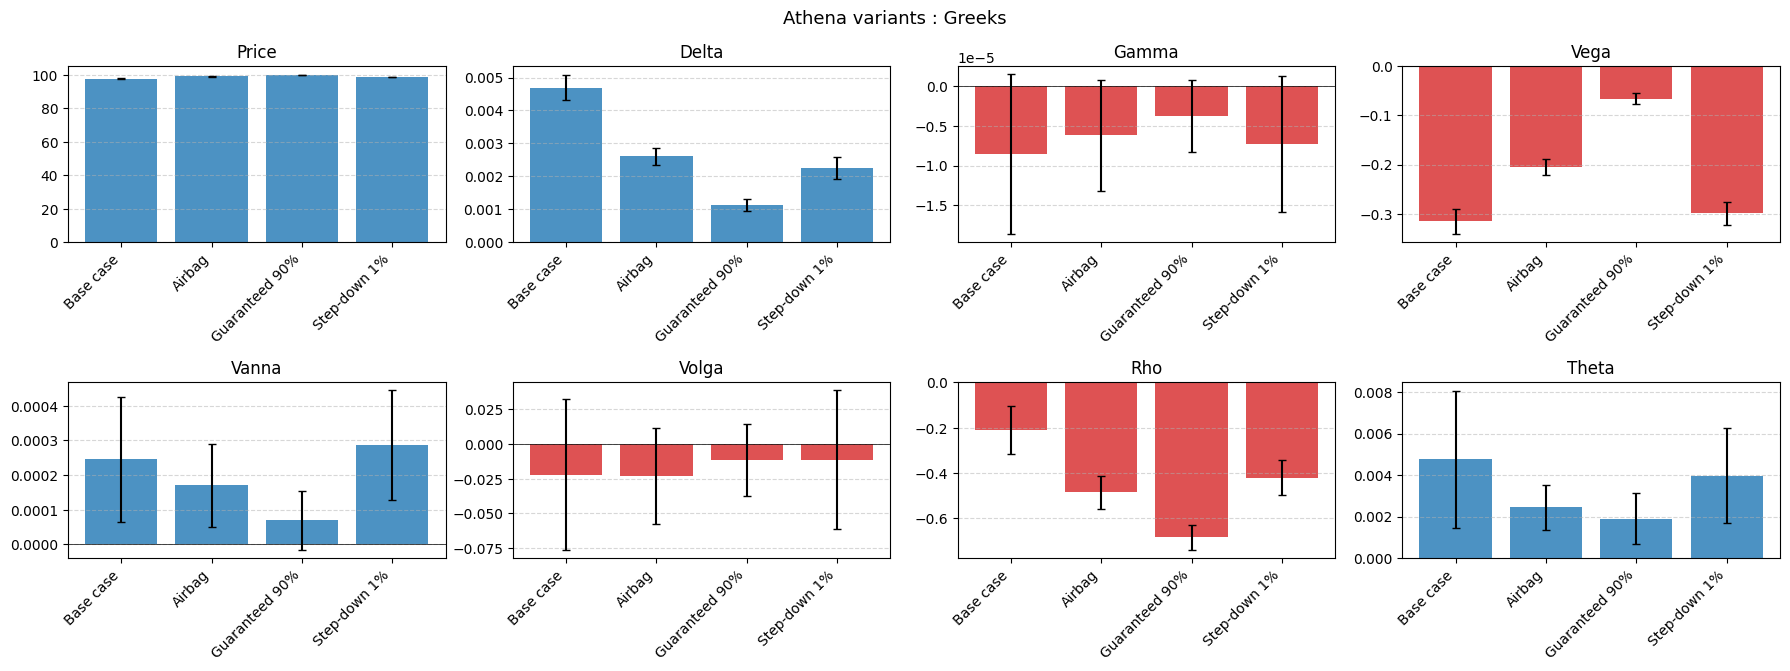

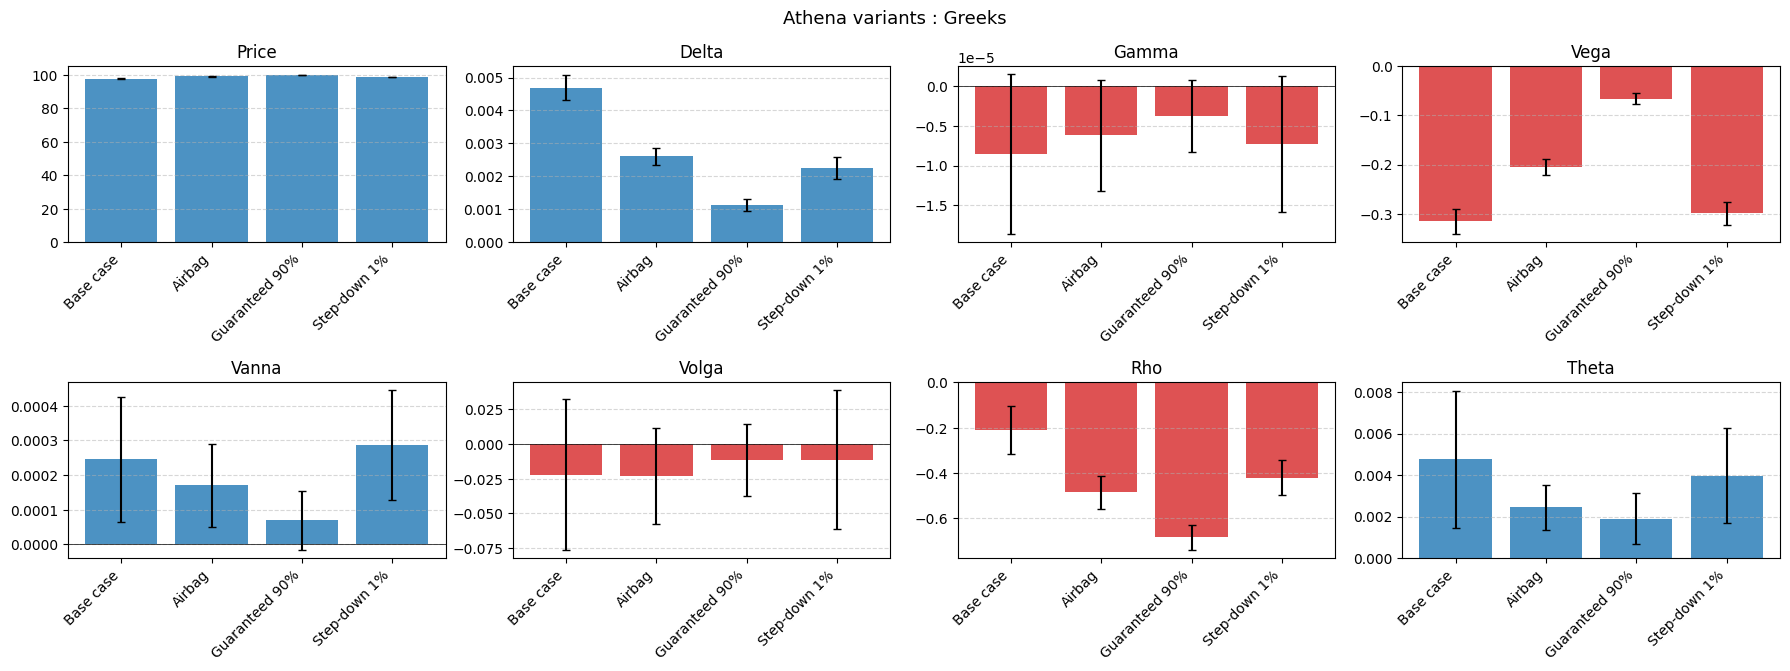

In [25]:
plot_greeks_bars(greeks, title="Athena variants : Greeks")

**Reading.** The investor is long the underlying (positive delta, through the call and the short put) and short volatility (negative vega) : a higher volatility makes the knock-in more likely. Flooring the capital removes most of the short put : the delta and the vega shrink, and the note behaves more like a zero-coupon bond, with a more negative rho.